# Extensión: pronóstico para todas las series viables

Autor: Juan Esteban Cardozo

El primer cuaderno (`analisis_prediccion.ipynb`) pronostica 25 series: 5 terminales por 5 operaciones, escogidas porque tenían buena historia. Aquí probamos si la misma solución sirve para las 47 x 46 = 2.162 combinaciones, que incluyen series casi vacías, terminales que dejaron de reportar y combinaciones que nunca se usaron.

Dejamos igual los datos, los festivos, las variables, la validación con cuatro cortes de 15 días y las métricas (WAPE, MAE y sesgo). El baseline sigue siendo el promedio por día de la semana. No tocamos el cuaderno original ni sus salidas; todo lo nuevo se guarda con el prefijo `ext_` en `outputs/`.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import PoissonRegressor

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .3, 'axes.titlesize': 11})
AZUL, NARANJA, GRIS = '#1f5f8b', '#d9822b', '#8a8a8a'
COLOR_SEG = {'viable': AZUL, 'rala': NARANJA, 'inactiva': GRIS}
T0 = time.time()

## Carga de datos

Igual que en el primer cuaderno, con una diferencia: el panel se arma con las 2.162 combinaciones aunque la mayoría no tenga registros, para que el universo quede completo.

In [2]:
ruta = None
for r in ['../data/data_01.txt', 'data/data_01.txt', 'data_01.txt']:
    if Path(r).exists():
        ruta = r
        break
if ruta is None:
    try:
        from google.colab import files
        ruta = list(files.upload())[0]   # subir data_01.txt
    except ImportError:
        raise FileNotFoundError('No encuentro data_01.txt, ponlo en la carpeta data/')

OUT = Path(ruta).resolve().parent.parent / 'outputs' if Path(ruta).parent.name == 'data' else Path('outputs')
OUT.mkdir(exist_ok=True)

df = pd.read_csv(ruta, sep='\t', parse_dates=['fecha'])
df['dia'] = df['fecha'].dt.normalize()

todos = pd.date_range('2017-01-31', '2017-05-31')
terms = sorted(df.idTerminal.unique())
opers = sorted(df.oper.unique())
malla = pd.MultiIndex.from_product([terms, opers], names=['idTerminal', 'oper'])

# todas las combinaciones, tengan o no registros
panel = df.groupby(['idTerminal', 'oper', 'dia']).size().unstack('dia').reindex(columns=todos).fillna(0)
panel = panel.reindex(malla, fill_value=0)
Y = panel.T
ys = Y.values.astype(float)
n, S = ys.shape
cod_t = np.array([terms.index(t) for t, _ in Y.columns])
cod_o = np.array([opers.index(o) for _, o in Y.columns])
print(df.shape, '| combinaciones:', S, '| combinaciones con al menos un registro:', int((ys.sum(0) > 0).sum()))

(775466, 4) | combinaciones: 2162 | combinaciones con al menos un registro: 1296


## A. Universo y segmentos

Clasificamos cada combinación con números que salen de su propia historia: días con actividad (de 121), media diaria desde su primer registro y días seguidos sin actividad al final. Definimos tres segmentos.

Viable: al menos 45 días con actividad y 3 o más transacciones por día desde el primer registro. Con 45 días hay unas seis semanas, lo mínimo para ver un patrón semanal, y por debajo de 3 por día la serie es sobre todo ceros y unos.

Inactiva: no tiene ningún registro, o lleva 7 días o más sin actividad y, con su ritmo anterior, habríamos esperado ver al menos 10 transacciones en esa pausa. Si el ritmo siguiera igual, un silencio así pasaría por azar unas 5 veces de cada 100.000. La regla atrapa a la 1963 y a la 1828 sin marcar como inactiva a una serie lenta que simplemente tiene huecos normales.

Rala: todo lo demás, es decir, series con actividad pero sin volumen o historia suficiente para un modelo propio.

Los umbrales los decidimos nosotros mirando la nube de puntos de la primera figura; no son un óptimo. Más abajo la validación nos dice si estuvieron bien puestos. En cada corte de la validación la segmentación se rehace usando solo los datos anteriores al corte.

In [3]:
# umbrales de segmentacion
DIAS_MIN = 45      # dias con actividad para ser viable
MEDIA_MIN = 3      # transacciones por dia (desde el primer registro) para ser viable
GAP_MIN = 7        # dias seguidos sin actividad para sospechar que dejo de reportar
ESPERA = 10        # transacciones que esperariamos haber visto en esa pausa

def segmentar(y):
    # clasifica cada serie usando solo las filas de y (los dias ya observados)
    m = len(y)
    act = y > 0
    dias = act.sum(0)
    tot = y.sum(0)
    prim = np.where(dias > 0, act.argmax(0), m)
    ult = np.where(dias > 0, m - 1 - act[::-1].argmax(0), -1)
    gap = m - 1 - ult
    tramo = np.maximum(ult - prim + 1, 1)                  # dias entre el primer y el ultimo registro
    media = np.where(dias > 0, tot / np.maximum(m - prim, 1), 0)
    inact = (dias == 0) | ((gap >= GAP_MIN) & (tot / tramo * gap >= ESPERA))
    viable = ~inact & (dias >= DIAS_MIN) & (media >= MEDIA_MIN)
    seg = np.where(inact, 'inactiva', np.where(viable, 'viable', 'rala'))
    return pd.DataFrame({'segmento': seg, 'total': tot, 'dias_activos': dias, 'media_diaria': media,
                         'primero': prim, 'dias_sin_actividad': gap}, index=Y.columns)

seg = segmentar(ys)
seg['motivo'] = np.where(seg.segmento == 'inactiva', np.where(seg.total == 0, 'sin registros', 'dejo de reportar'),
                         np.where(seg.segmento == 'rala', 'poco volumen o historia', 'historia y volumen suficientes'))
tab = seg.groupby('segmento').agg(combinaciones=('total', 'size'), transacciones=('total', 'sum'))
tab['pct_combinaciones'] = (tab.combinaciones / S * 100).round(1)
tab['pct_volumen'] = (tab.transacciones / seg.total.sum() * 100).round(2)
print(tab.loc[['viable', 'rala', 'inactiva']].to_string())
print()
print(seg.groupby(['segmento', 'motivo']).agg(combinaciones=('total', 'size'), transacciones=('total', 'sum')).to_string())

          combinaciones  transacciones  pct_combinaciones  pct_volumen
segmento                                                              
viable              235       693206.0               10.9        89.39
rala                843        45771.0               39.0         5.90
inactiva           1084        36489.0               50.1         4.71

                                         combinaciones  transacciones
segmento motivo                                                      
inactiva dejo de reportar                          218        36489.0
         sin registros                             866            0.0
rala     poco volumen o historia                   843        45771.0
viable   historia y volumen suficientes            235       693206.0


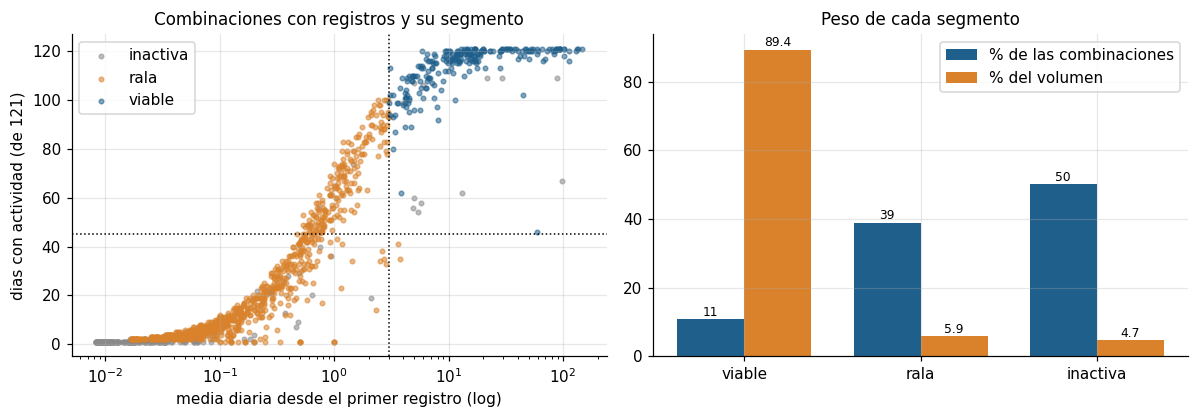

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.9))
obs = seg[seg.total > 0]
for s_, g in obs.groupby('segmento'):
    axs[0].scatter(g.media_diaria.clip(lower=.003), g.dias_activos, s=9, alpha=.55, color=COLOR_SEG[s_], label=s_)
axs[0].set_xscale('log'); axs[0].axvline(MEDIA_MIN, color='black', ls=':', lw=1); axs[0].axhline(DIAS_MIN, color='black', ls=':', lw=1)
axs[0].set_xlabel('media diaria desde el primer registro (log)'); axs[0].set_ylabel('dias con actividad (de 121)')
axs[0].set_title('Combinaciones con registros y su segmento'); axs[0].legend()
orden = ['viable', 'rala', 'inactiva']
x = np.arange(3); w = .38
axs[1].bar(x - w / 2, tab.loc[orden, 'pct_combinaciones'], w, color=AZUL, label='% de las combinaciones')
axs[1].bar(x + w / 2, tab.loc[orden, 'pct_volumen'], w, color=NARANJA, label='% del volumen')
axs[1].set_xticks(x); axs[1].set_xticklabels(orden); axs[1].legend(); axs[1].set_title('Peso de cada segmento')
for i_, s_ in enumerate(orden):
    axs[1].text(i_ - w / 2, tab.loc[s_, 'pct_combinaciones'] + 1, f"{tab.loc[s_, 'pct_combinaciones']:.0f}", ha='center', fontsize=8)
    axs[1].text(i_ + w / 2, tab.loc[s_, 'pct_volumen'] + 1, f"{tab.loc[s_, 'pct_volumen']:.1f}", ha='center', fontsize=8)
fig.tight_layout(); fig.savefig(OUT / 'ext_fig01_segmentos.png'); plt.show()

Quedan 235 combinaciones viables (10,9% del total) que concentran 89,4% de las transacciones. Las 843 ralas (39,0%) aportan solo 5,9%. Las 1.084 inactivas (50,1%) se dividen en 866 que no tienen un solo registro y 218 que dejaron de reportar; estas últimas sumaban 36.489 transacciones (4,7% del total).

En la figura, las líneas punteadas son los umbrales. Las viables ocupan la esquina superior derecha; las ralas forman una curva continua que baja hasta casi cero, así que cualquier umbral sobre ella es en parte arbitrario. Los puntos grises con volumen alto y pocos días activos son las series de la 1963 y la 1828.

In [5]:
# terminales que dejaron de reportar o aparecieron tarde
t_dia = df.groupby('idTerminal').dia.agg(['min', 'max'])
t_dia['dias_sin_reportar'] = (todos[-1] - t_dia['max']).dt.days
t_dia['series_inactivas_con_registros'] = seg[(seg.segmento == 'inactiva') & (seg.total > 0)].groupby(level=0).size()
t_dia['series_viables'] = seg[seg.segmento == 'viable'].groupby(level=0).size()
t_dia = t_dia.fillna(0).astype({'series_inactivas_con_registros': int, 'series_viables': int})
print(t_dia[(t_dia['min'] > '2017-02-01') | (t_dia.dias_sin_reportar > 0)].to_string())
print()
print('terminales sin ninguna serie viable:', t_dia.index[t_dia.series_viables == 0].tolist())

                  min        max  dias_sin_reportar  series_inactivas_con_registros  series_viables
idTerminal                                                                                         
1515       2017-04-06 2017-05-31                  0                               3               1
1828       2017-01-31 2017-05-19                 12                              18               0
1963       2017-01-31 2017-04-07                 54                              26               0

terminales sin ninguna serie viable: [1828, 1963]


La 1963 deja de reportar el 7 de abril (54 días antes del final) y la 1828 el 19 de mayo (12 días). Entre las dos suman 44 series inactivas con registros y ninguna viable. La 1515, que apareció el 6 de abril, queda con una sola serie viable: tiene 56 días de historia y sus demás series quedan como ralas o inactivas.

## B. Modelado

Cada segmento se trata distinto.

Las viables usan lo mismo que ganó en el 5x5: el promedio simple de dos modelos. Uno es una regresión de Poisson por serie con día de la semana, festivo, cercanía al borde del mes y quincena. El otro es un gradient boosting de Poisson global con rezagos del mismo día de la semana, medias recientes, horizonte y calendario.

Las ralas se pronostican con un método simple (promedio por día de la semana o media móvil de 28 días) y se marcan con baja confiabilidad. Las inactivas se pronostican en 0 y llevan una marca que lo dice.

Festivos: son los mismos del cuaderno original, tomados del calendario colombiano de 2017 porque no vienen en los datos. Del 1 al 15 de junio no hay ninguno (el 19 y el 26 caen fuera de la ventana), así que la variable de festivo vale 0 en todo el pronóstico.

Diferencias con el 5x5:

- No volvimos a comparar los nueve métodos. Fijamos la mezcla que ya había ganado, así que la validación mide ese modelo y el baseline, no una nueva selección.
- El Poisson sigue siendo uno por serie. Con unas 240 series viables ajusta en segundos, así que no vimos necesidad de un modelo global con identificadores. Lo que sí vectorizamos es la construcción de variables del boosting, que antes se armaba fila por fila y con 2.162 series habría sido muy lento.
- Terminal y operación entran al boosting como categorías (en el 5x5 eran la posición dentro de la grilla de 5x5). El boosting se entrena solo con las viables.
- Cada serie se entrena desde su primer día con actividad. Así la 1515, que aparece tarde, no arrastra semanas de ceros falsos.
- No calculamos rangos de incertidumbre, que el 5x5 sí tenía; no alcanzamos a hacerlo para 2.162 series.

In [6]:
H = 15
FEST = pd.to_datetime(['2017-01-09', '2017-03-20', '2017-04-13', '2017-04-14', '2017-05-01',
                       '2017-05-29', '2017-06-19', '2017-06-26'])
FESTSET = set(FEST)
fechas = pd.date_range('2017-01-31', '2017-06-15')
def es_fest(d): return int(pd.Timestamp(d) in FESTSET)

def borde_mes(d):
    # dias que faltan al borde de mes mas cercano (0 el dia 1 y el ultimo dia)
    return min(d.day - 1, d.days_in_month - d.day)

def dummies(fs):
    X = np.column_stack([np.eye(7)[[d.dayofweek for d in fs]], [es_fest(d) for d in fs]])
    extra = np.column_stack([[np.exp(-borde_mes(d) / 4) for d in fs], [int(d.day in (15, 16)) for d in fs]])
    return np.column_stack([X, extra])

XCAL = dummies(fechas)    # se calcula una vez para todo el calendario

def glm_calendario(o, cols, prim):
    # un Poisson por serie, entrenado desde su primer dia con actividad
    sal = np.zeros((H, len(cols)))
    for k, s in enumerate(cols):
        g = PoissonRegressor(alpha=1e-6, max_iter=500).fit(XCAL[prim[s]:o], ys[prim[s]:o, s])
        sal[:, k] = g.predict(XCAL[o:o + H])
    return sal

def boosting_global(o, cols, prim):
    # el mismo boosting global del 5x5, pero las variables se arman para todas las series a la vez
    Ys = ys[:, cols]
    m = len(cols)
    cs = np.vstack([np.zeros(m), Ys.cumsum(0)])
    pr = prim[cols]
    def variables(i, h):
        j = i + h; f = fechas[j]
        b = j - 7 * (h // 7 + 1)                       # mismo dia de la semana ya observado
        lags = np.mean([Ys[b - 7 * q] for q in range(4)], axis=0)
        m28 = (cs[i] - cs[i - 28]) / 28
        uno = np.ones(m)
        return np.column_stack([f.dayofweek * uno, es_fest(f) * uno, h * uno, Ys[b], lags, (cs[i] - cs[i - 7]) / 7,
                                m28, Ys[i - 1], np.log1p(m28), f.day * uno, borde_mes(f) * uno,
                                cod_t[cols], cod_o[cols]])
    X, t = [], []
    for i in range(28, o):
        ok = i >= pr                                    # la serie ya existia en el origen
        for h in range(H):
            if i + h <= o - 1:
                X.append(variables(i, h)[ok]); t.append(Ys[i + h][ok])
    X, t = np.vstack(X), np.concatenate(t)
    mod = HistGradientBoostingRegressor(loss='poisson', max_iter=200, learning_rate=.05, max_depth=4,
                                        min_samples_leaf=20, categorical_features=[0, 11, 12], random_state=0)
    mod.fit(X, t)
    p = mod.predict(np.vstack([variables(o, h) for h in range(H)]))
    return p.reshape(H, m), len(t)

def prom_dia_sem(o):
    return np.array([np.mean([ys[o - 7 + (h % 7) - 7 * q] for q in range(4)], axis=0) for h in range(H)])

def media_movil28(o):
    return np.tile(ys[o - 28:o].mean(0), (H, 1))

def sistema(o):
    # todo lo que se pronostica con los datos anteriores al indice o
    sg = segmentar(ys[:o])
    viab = np.where(sg.segmento == 'viable')[0]
    mezcla = np.full((H, S), np.nan)
    muestras = 0
    if len(viab):
        glm = glm_calendario(o, viab, sg.primero.values)
        gb, muestras = boosting_global(o, viab, sg.primero.values)
        mezcla[:, viab] = (glm + gb) / 2
    return dict(seg=sg, mezcla=mezcla, base=prom_dia_sem(o), mm28=media_movil28(o), muestras=muestras)

def tabla_larga(o, r):
    fs = fechas[o:o + H]
    real = ys[o:o + H] if o + H <= n else np.full((H, S), np.nan)
    return pd.DataFrame({
        'corte': str(fechas[o].date()), 'terminal': np.tile(Y.columns.get_level_values(0), H),
        'oper': np.tile(Y.columns.get_level_values(1), H), 'fecha': np.repeat(fs, S),
        'segmento': np.tile(r['seg'].segmento.values, H), 'vol28': np.tile(ys[o - 28:o].mean(0), H),
        'real': real.ravel(), 'mezcla': r['mezcla'].ravel(), 'base': r['base'].ravel(), 'mm28': r['mm28'].ravel()})

## C. Validación

Mismos cuatro cortes de 15 días. El nombre de cada corte es el primer día pronosticado (2 de abril, 17 de abril, 2 de mayo y 17 de mayo; el último es la prueba). En cada corte se segmenta, se entrena y se pronostica usando solo lo anterior.

In [7]:
ORIGENES = [n - 60, n - 45, n - 30, n - 15]
folds = []
for o in ORIGENES:
    t1 = time.time()
    r = sistema(o)
    folds.append(tabla_larga(o, r))
    c = r['seg'].segmento.value_counts()
    print(f"corte {fechas[o].date()}: viables {c.get('viable', 0)}, ralas {c.get('rala', 0)}, inactivas {c.get('inactiva', 0)}"
          f" | muestras del boosting {r['muestras']:,} | {time.time() - t1:.0f} s")
val = pd.concat(folds, ignore_index=True)
print('tiempo acumulado:', round(time.time() - T0), 's')

corte 2017-04-02: viables 246, ralas 743, inactivas 1173 | muestras del boosting 95,940 | 3 s


corte 2017-04-17: viables 242, ralas 736, inactivas 1184 | muestras del boosting 148,830 | 3 s


corte 2017-05-02: viables 241, ralas 778, inactivas 1143 | muestras del boosting 202,440 | 3 s


corte 2017-05-17: viables 243, ralas 815, inactivas 1104 | muestras del boosting 258,795 | 4 s
tiempo acumulado: 15 s


In [8]:
def metricas(d, col):
    # WAPE, MAE y sesgo por corte, promediados entre cortes (igual que en el 5x5)
    r = []
    for _, g in d.groupby('corte'):
        e = g[col] - g.real
        s_real = g.real.sum()
        r.append([np.abs(e).sum() / s_real if s_real > 0 else np.nan, np.abs(e).mean(), e.sum() / s_real if s_real > 0 else np.nan])
    return pd.Series(np.nanmean(r, axis=0), index=['WAPE', 'MAE', 'sesgo'])

# metodo para las ralas: promedio por dia de la semana o media movil de 28 dias
ral = val[val.segmento == 'rala']
cmp_ral = pd.DataFrame({m: metricas(ral, m) for m in ['base', 'mm28']}).T.round(3)
cmp_ral.index = ['promedio por dia de la semana', 'media movil 28 dias']
print(cmp_ral.to_string())
METODO_RALA = 'base' if cmp_ral.WAPE.iloc[0] <= cmp_ral.WAPE.iloc[1] else 'mm28'
print('metodo para ralas:', METODO_RALA)

                                WAPE    MAE  sesgo
promedio por dia de la semana  1.109  0.597 -0.043
media movil 28 dias            1.127  0.607 -0.039
metodo para ralas: base


Para las ralas el promedio por día de la semana (WAPE 1,109) y la media móvil de 28 días (1,127) casi empatan, así que usamos el promedio por día de la semana. Es también el baseline, por lo que en ese segmento el sistema y el baseline dan lo mismo. No buscamos mejorar ahí; solo marcamos las series como poco confiables. Un WAPE de 1,1 significa que el error absoluto es mayor que lo que realmente ocurrió.

In [9]:
def pred_sistema(d):
    # viables: mezcla; ralas: metodo simple; inactivas: cero
    return np.where(d.segmento == 'viable', d.mezcla, np.where(d.segmento == 'rala', d[METODO_RALA], 0.0))
val['pred'] = pred_sistema(val)

def agregar(d, clave):
    # suma las series por terminal u operacion y fecha antes de medir el error
    return d.groupby(['corte', clave, 'fecha'])[['real', 'pred', 'base']].sum().reset_index()

ULTIMO = str(fechas[ORIGENES[-1]].date())
def fila(d, nivel, seg_, clave):
    a, b = metricas(d, 'pred'), metricas(d, 'base')
    dt = d[d.corte == ULTIMO]
    k = d[['terminal', 'oper']].drop_duplicates().shape[0] if clave == 'serie' else d[clave].nunique()
    unidades = k
    return dict(nivel=nivel, segmento=seg_, unidades=unidades,
                WAPE_modelo=a.WAPE, WAPE_base=b.WAPE, MAE_modelo=a.MAE, MAE_base=b.MAE,
                sesgo_modelo=a.sesgo, sesgo_base=b.sesgo,
                WAPE_modelo_prueba=metricas(dt, 'pred').WAPE, WAPE_base_prueba=metricas(dt, 'base').WAPE,
                transacciones_reales_por_corte=d.real.sum() / 4)

filas = []
grupos = {'viable': ['viable'], 'rala': ['rala'], 'viable+rala': ['viable', 'rala'], 'inactiva': ['inactiva'],
          'todas': ['viable', 'rala', 'inactiva']}
for nombre, segs in grupos.items():
    d = val[val.segmento.isin(segs)]
    filas.append(fila(d, 'serie', nombre, 'serie'))
    filas.append(fila(agregar(d, 'terminal'), 'terminal', nombre, 'terminal'))
    filas.append(fila(agregar(d, 'oper'), 'operacion', nombre, 'oper'))
met = pd.DataFrame(filas)
met.to_csv(OUT / 'ext_metricas_por_segmento.csv', index=False, float_format='%.4f')
print(met.round(3).to_string(index=False))

    nivel    segmento  unidades  WAPE_modelo  WAPE_base  MAE_modelo  MAE_base  sesgo_modelo  sesgo_base  WAPE_modelo_prueba  WAPE_base_prueba  transacciones_reales_por_corte
    serie      viable       252        0.366      0.480       8.584    11.251        -0.036       0.003               0.353             0.503                        85961.50
 terminal      viable        46        0.299      0.416      37.616    52.280        -0.036       0.003               0.279             0.432                        85961.50
operacion      viable        10        0.185      0.319     114.616   196.113        -0.036       0.003               0.155             0.325                        85961.50
    serie        rala       896        1.109      1.109       0.597     0.597        -0.043      -0.043               1.091             1.091                         6300.50
 terminal        rala        47        0.591      0.591       5.194     5.194        -0.043      -0.043               0.552       

In [10]:
# el 5x5 sobre las mismas 25 series, para comparar (valores de resumen.json del primer cuaderno)
import json
try:
    r5 = json.load(open(OUT / 'resumen.json'))
    print('5x5 en prueba: WAPE modelo', r5['wape_modelo_test'], '| base', r5['wape_base_test'], '| MAE', r5['mae_modelo_test'])
    print('5x5 promedio de 4 cortes: WAPE modelo', r5['wape_modelo_prom'], '| base', r5['wape_base_prom'])
except FileNotFoundError:
    print('no encuentro resumen.json del primer cuaderno')

5x5 en prueba: WAPE modelo 0.322 | base 0.445 | MAE 11.64
5x5 promedio de 4 cortes: WAPE modelo 0.35 | base 0.453


En las viables el sistema baja el WAPE de 0,48 (baseline) a 0,37 por serie, y el MAE de 11,3 a 8,6 transacciones por serie y día. En el corte de prueba (17 al 31 de mayo) pasa de 0,50 a 0,35. El sesgo es de -3,6%: el sistema se queda un poco corto.

Sobre todas las series el WAPE es 0,42 contra 0,53 del baseline. El MAE global (1,19 contra 1,51) se ve pequeño porque casi la mitad de las series son ceros; no es comparable con el del 5x5. Cuando sumamos las series, el error baja: por terminal el WAPE es 0,30 contra 0,42, y por operación 0,20 contra 0,33. En las operaciones solo hay 10 con series viables, y ahí el sistema da 0,185.

Las inactivas pronosticadas en 0 pierden en promedio 286 transacciones por corte (algo que el WAPE de 1,0 refleja por definición), pero el baseline hace algo peor: al repetir las últimas cuatro semanas sigue proyectando actividad en series que ya pararon, y sobreestima más de tres veces lo real. Hay un caso que no se podía prever: el corte del 17 de mayo es anterior a la salida de la 1828 (19 de mayo), así que esas series se pronosticaron como activas.

Frente al 5x5, las viables quedan algo peor (0,37 contra 0,35 en el promedio de cortes; 0,35 contra 0,32 en la prueba). Tiene sentido: en el 5x5 escogimos series con buena historia, aquí entran también las más pequeñas.

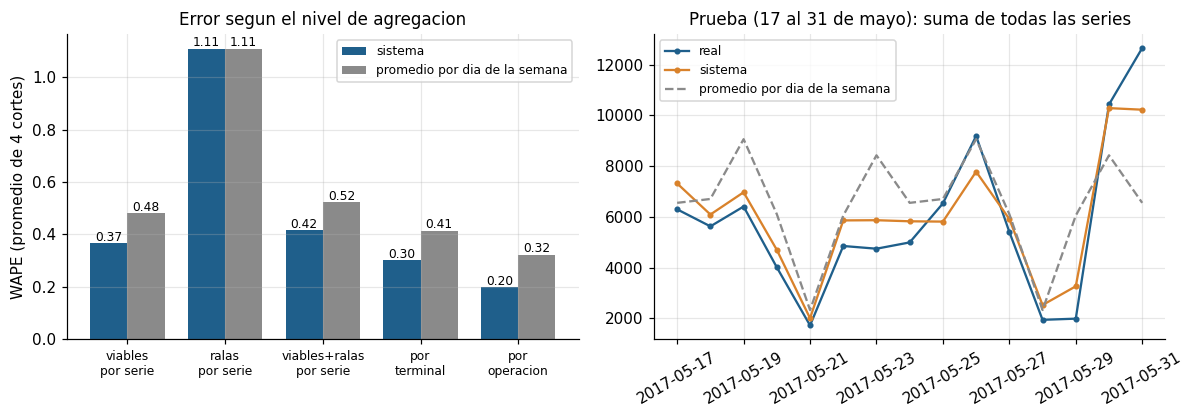

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.9))
cats = [('viable', 'serie'), ('rala', 'serie'), ('viable+rala', 'serie'), ('viable+rala', 'terminal'), ('viable+rala', 'operacion')]
nom = ['viables\npor serie', 'ralas\npor serie', 'viables+ralas\npor serie', 'por\nterminal', 'por\noperacion']
v = [met[(met.segmento == s_) & (met.nivel == n_)].iloc[0] for s_, n_ in cats]
x = np.arange(len(v)); w = .38
axs[0].bar(x - w / 2, [a.WAPE_modelo for a in v], w, color=AZUL, label='sistema')
axs[0].bar(x + w / 2, [a.WAPE_base for a in v], w, color=GRIS, label='promedio por dia de la semana')
for i_, a in enumerate(v):
    axs[0].text(i_ - w / 2, a.WAPE_modelo + .01, f'{a.WAPE_modelo:.2f}', ha='center', fontsize=8)
    axs[0].text(i_ + w / 2, a.WAPE_base + .01, f'{a.WAPE_base:.2f}', ha='center', fontsize=8)
axs[0].set_xticks(x); axs[0].set_xticklabels(nom, fontsize=8); axs[0].set_ylabel('WAPE (promedio de 4 cortes)')
axs[0].set_title('Error segun el nivel de agregacion'); axs[0].legend(fontsize=8)

ult = val[val.corte == ULTIMO].groupby('fecha')[['real', 'pred', 'base']].sum()
axs[1].plot(ult.index, ult.real, color=AZUL, marker='o', ms=3, label='real')
axs[1].plot(ult.index, ult.pred, color=NARANJA, marker='o', ms=3, label='sistema')
axs[1].plot(ult.index, ult.base, color=GRIS, ls='--', label='promedio por dia de la semana')
axs[1].set_title('Prueba (17 al 31 de mayo): suma de todas las series'); axs[1].legend(fontsize=8); axs[1].tick_params(axis='x', rotation=30)
fig.tight_layout(); fig.savefig(OUT / 'ext_fig02_error_niveles.png'); plt.show()

En la izquierda se ve cómo baja el error al agregar. Una sola serie viable se pronostica con WAPE 0,37, la suma por terminal con 0,30 y la suma por operación con 0,20, y el sistema le gana al baseline en los tres niveles. La barra de las ralas es igual para ambos porque usamos el mismo método.

A la derecha, la suma de todas las series en la prueba. El sistema sigue bien la caída de los domingos y el salto de los dos últimos días del mes, que el baseline no alcanza. También se nota el festivo del 29 de mayo, que el modelo sobrestima.

       series_corte  vol_min  vol_mediana  vol_max  pct_viables  pct_volumen  WAPE_modelo  WAPE_base
decil                                                                                               
1               378     0.04         0.04     0.04         0.00         0.09         1.56       1.56
2               378     0.04         0.07     0.07         0.00         0.15         1.54       1.54
3               378     0.07         0.11     0.14         0.00         0.19         1.71       1.71
4               378     0.14         0.21     0.29         0.00         0.33         1.66       1.66
5               378     0.29         0.39     0.54         0.00         0.66         1.40       1.40
6               378     0.54         0.68     0.93         0.26         1.10         1.24       1.23
7               378     0.93         1.25     1.86         0.26         1.92         1.03       1.03
8               378     1.86         3.14     5.79        57.67         5.38         0.67  

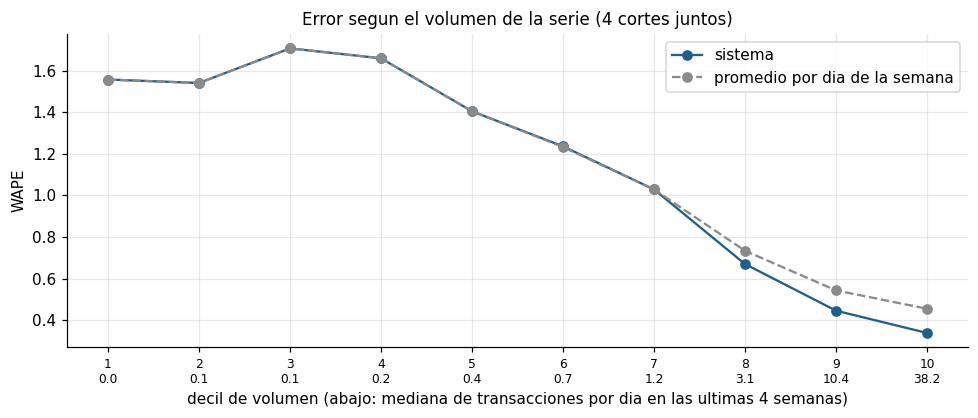

In [12]:
# error segun el volumen de la serie: una fila por serie y corte
act = val[val.segmento.isin(['viable', 'rala']) & (val.vol28 > 0)].copy()
act['ae_modelo'] = (act.pred - act.real).abs()
act['ae_base'] = (act.base - act.real).abs()
sf = act.groupby(['corte', 'terminal', 'oper']).agg(vol=('vol28', 'first'), real=('real', 'sum'), ae_modelo=('ae_modelo', 'sum'),
                                                   ae_base=('ae_base', 'sum'), segmento=('segmento', 'first')).reset_index()
sf['decil'] = pd.qcut(sf.vol.rank(method='first'), 10, labels=False) + 1
dec = sf.groupby('decil').agg(series_corte=('vol', 'size'), vol_min=('vol', 'min'), vol_mediana=('vol', 'median'), vol_max=('vol', 'max'),
                              pct_viables=('segmento', lambda s: (s == 'viable').mean() * 100),
                              real=('real', 'sum'), ae_modelo=('ae_modelo', 'sum'), ae_base=('ae_base', 'sum'))
dec['WAPE_modelo'] = dec.ae_modelo / dec.real
dec['WAPE_base'] = dec.ae_base / dec.real
dec['pct_volumen'] = dec.real / dec.real.sum() * 100
print(dec[['series_corte', 'vol_min', 'vol_mediana', 'vol_max', 'pct_viables', 'pct_volumen', 'WAPE_modelo', 'WAPE_base']].round(2).to_string())

fig, ax = plt.subplots(figsize=(9, 3.9))
ax.plot(dec.index, dec.WAPE_modelo, color=AZUL, marker='o', label='sistema')
ax.plot(dec.index, dec.WAPE_base, color=GRIS, marker='o', ls='--', label='promedio por dia de la semana')
ax.set_xticks(dec.index); ax.set_xticklabels([f'{i}\n{m:.1f}' for i, m in zip(dec.index, dec.vol_mediana)], fontsize=8)
ax.set_xlabel('decil de volumen (abajo: mediana de transacciones por dia en las ultimas 4 semanas)'); ax.set_ylabel('WAPE')
ax.set_title('Error segun el volumen de la serie (4 cortes juntos)'); ax.legend()
fig.tight_layout(); fig.savefig(OUT / 'ext_fig03_wape_deciles.png'); plt.show()

Dividimos las series (por corte) en diez grupos del mismo tamaño según su volumen diario de las últimas cuatro semanas. En los siete primeros (hasta unas 1,9 transacciones por día) el WAPE va de 1,03 a 1,71, sin diferencia con el baseline porque casi no hay series viables. En el octavo (mediana de 3,1 por día) baja a 0,67 contra 0,73; en el noveno (10,4 por día) a 0,45 contra 0,54; y en el décimo (38 por día) a 0,34 contra 0,46.

El décimo decil concentra 74% del volumen de las series con actividad y los dos últimos juntos 90%. O sea, la prueba real del modelo está donde se concentra la demanda.

In [13]:
# con que volumen el WAPE del sistema baja de ciertos niveles (bandas fijas, mas faciles de leer que los deciles)
bandas = [0, 1, 2, 5, 10, 20, 50, 1e9]
sf['banda'] = pd.cut(sf.vol, bandas, right=False)
ban = sf.groupby('banda', observed=True).agg(series_corte=('vol', 'size'), real=('real', 'sum'), ae_modelo=('ae_modelo', 'sum'), ae_base=('ae_base', 'sum'))
ban['WAPE_modelo'] = ban.ae_modelo / ban.real
ban['WAPE_base'] = ban.ae_base / ban.real
print(ban[['series_corte', 'WAPE_modelo', 'WAPE_base']].round(2).to_string())
g = sf[sf.vol >= 10]
print('\nseries con 10 o mas transacciones por dia:', len(g), 'series-corte | WAPE sistema', round(g.ae_modelo.sum() / g.real.sum(), 3), '| base', round(g.ae_base.sum() / g.real.sum(), 3),
      '| pesan', round(g.real.sum() / sf.real.sum() * 100, 1), '% del volumen')

                      series_corte  WAPE_modelo  WAPE_base
banda                                                     
[0.0, 1.0)                    2312         1.39       1.39
[1.0, 2.0)                     364         1.01       1.01
[2.0, 5.0)                     302         0.69       0.74
[5.0, 10.0)                    218         0.52       0.62
[10.0, 20.0)                   296         0.40       0.50
[20.0, 50.0)                   153         0.37       0.47
[50.0, 1000000000.0)           135         0.32       0.45

series con 10 o mas transacciones por dia: 584 series-corte | WAPE sistema 0.348 | base 0.462 | pesan 84.8 % del volumen


Con bandas fijas de volumen se lee mejor el límite. Desde 10 transacciones por día el WAPE es 0,40 o menos (0,40, 0,37 y 0,32 en las bandas 10-20, 20-50 y 50 o más). Entre 5 y 10 está en 0,52, entre 2 y 5 en 0,69, entre 1 y 2 en 1,01 y bajo 1 por día en 1,39. Las series con 10 o más por día tienen WAPE 0,348 contra 0,462 del baseline y pesan 85% del volumen.

Con esto, el pronóstico por serie nos parece confiable desde unas 10 transacciones diarias, útil con reservas entre 2 y 10, y poco servido para decidir por debajo de 2 por día; ahí solo miraríamos agregados. Ojo: elegimos este corte viendo los mismos datos de validación, así que probablemente es algo optimista.

## D. Pronóstico final

Reentrenamos con los 121 días, volvemos a segmentar con toda la historia y pronosticamos del 1 al 15 de junio de 2017 para las 2.162 series. Con el último origen, el boosting entrena con unas 300 mil muestras.

In [14]:
t1 = time.time()
rf = sistema(n)
sgf = rf['seg']
pred_f = np.where(sgf.segmento == 'viable', rf['mezcla'], np.where(sgf.segmento == 'rala', rf[METODO_RALA], 0.0))
pred_f = np.clip(pred_f, 0, None)
print('reentrenamiento final:', round(time.time() - t1), 's | muestras del boosting', f"{rf['muestras']:,}")

reentrenamiento final: 4 s | muestras del boosting 302,595


Marcamos la confiabilidad con lo que vimos en la validación: alta para las viables con 10 o más transacciones diarias (WAPE cercano a 0,4 o mejor), media para el resto de las viables, baja para las ralas. Las inactivas llevan la marca de que no hay actividad reciente y se asume 0. Esa suposición no detecta una reactivación; si una de esas terminales vuelve a reportar, el pronóstico quedará bajo hasta que se vuelva a entrenar.

Las 141 series de confiabilidad alta suman 83.225 transacciones pronosticadas (85% del total), las 94 medias 9.409 (10%) y las 843 ralas 5.653 (6%).

In [15]:
VOL_ALTA = 10    # transacciones por dia (ultimas 4 semanas) desde las que la viable se marca como alta

vol28_f = ys[-28:].mean(0)
conf = np.where(sgf.segmento == 'viable', np.where(vol28_f >= VOL_ALTA, 'alta', 'media'),
                np.where(sgf.segmento == 'rala', 'baja', 'sin actividad reciente, se asume 0'))
fs_f = fechas[n:n + H]
pred = pd.DataFrame({'terminal': np.tile(Y.columns.get_level_values(0), H), 'operación': np.tile(Y.columns.get_level_values(1), H),
                     'fecha': np.repeat(fs_f.date, S), 'pronóstico': pred_f.ravel().round(2),
                     'segmento': np.tile(sgf.segmento.values, H), 'confiabilidad': np.tile(conf, H)})
pred.to_csv(OUT / 'ext_predicciones_15dias_todas.csv', index=False, encoding='utf-8-sig')
print(pred.shape)
print(pred.groupby(['segmento', 'confiabilidad']).agg(series=('terminal', lambda s: len(s) // H), total_15dias=('pronóstico', 'sum')).round(0).to_string())
pred.head(6)

(32430, 6)
                                             series  total_15dias
segmento confiabilidad                                           
inactiva sin actividad reciente, se asume 0    1084           0.0
rala     baja                                   843        5653.0
viable   alta                                   141       83225.0
         media                                   94        9409.0


,terminal,operación,fecha,pronóstico,segmento,confiabilidad
0,1507,0,2017-06-01,27.51,viable,alta
1,1507,1,2017-06-01,6.36,viable,media
2,1507,2,2017-06-01,0.25,rala,baja
3,1507,3,2017-06-01,8.97,viable,media
4,1507,4,2017-06-01,0.00,rala,baja
5,1507,5,2017-06-01,1.00,rala,baja


In [16]:
# totales por terminal y por operacion: diario y de la ventana, con los 15 dias reales anteriores
def resumen_pron(clave, nombre):
    p = pred.pivot_table(index=clave, columns='fecha', values='pronóstico', aggfunc='sum')
    p.columns = [str(c) for c in p.columns]
    p['total_ventana'] = p.sum(axis=1)
    prev = pd.Series(ys[-H:].sum(0), index=Y.columns).groupby(level=0 if clave == 'terminal' else 1).sum()
    p['reales_15_dias_previos'] = prev.reindex(p.index).values
    p['variacion_pct'] = ((p.total_ventana / p.reales_15_dias_previos - 1) * 100).where(p.reales_15_dias_previos > 0)
    p['participacion_pct'] = p.total_ventana / p.total_ventana.sum() * 100
    p = p.sort_values('total_ventana', ascending=False).round(2)
    p.index.name = nombre
    return p

por_term = resumen_pron('terminal', 'terminal')
por_op = resumen_pron('operación', 'operación')
por_term.to_csv(OUT / 'ext_pronostico_por_terminal.csv', encoding='utf-8-sig')
por_op.to_csv(OUT / 'ext_pronostico_por_operacion.csv', encoding='utf-8-sig')
print('total pronosticado 1-15 de junio:', int(round(pred['pronóstico'].sum())), '| reales 17-31 de mayo:', int(ys[-H:].sum()))
print('\nterminales con mas demanda proyectada')
print(por_term[['total_ventana', 'reales_15_dias_previos', 'variacion_pct', 'participacion_pct']].head(10).to_string())
print('\noperaciones')
print(por_op[['total_ventana', 'reales_15_dias_previos', 'variacion_pct', 'participacion_pct']].head(6).to_string())

total pronosticado 1-15 de junio:

 98287 | reales 17-31 de mayo: 86761

terminales con mas demanda proyectada
          total_ventana  reales_15_dias_previos  variacion_pct  participacion_pct
terminal                                                                         
1774            4142.39                  3687.0          12.35               4.21
1908            3845.21                  2935.0          31.01               3.91
1910            3678.30                  3429.0           7.27               3.74
1964            3399.61                  2583.0          31.61               3.46
1980            3330.96                  3362.0          -0.92               3.39
1593            3260.67                  2807.0          16.16               3.32
1741            2937.72                  2509.0          17.09               2.99
1824            2926.72                  2970.0          -1.46               2.98
1864            2903.78                  2312.0          25.60               2.95
1896            2839.8

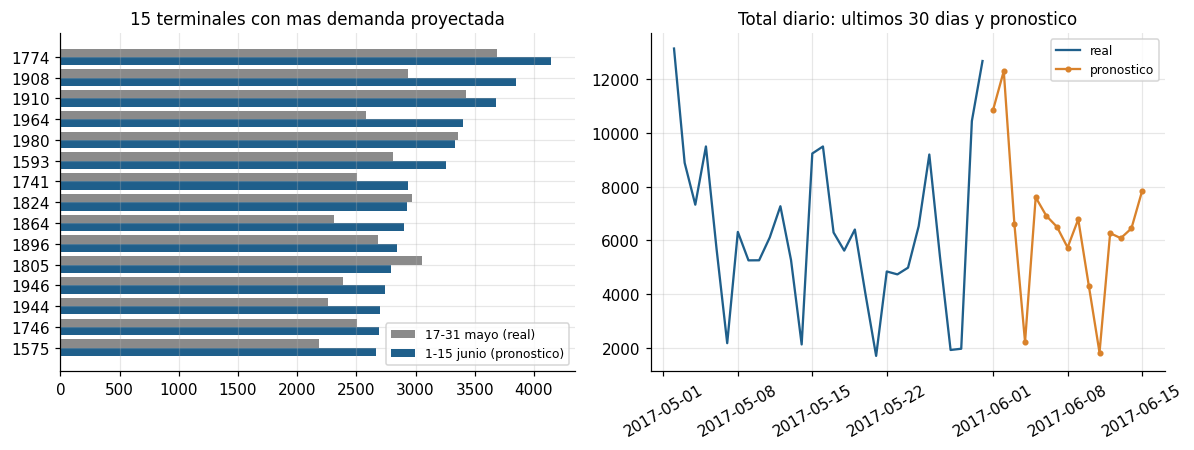

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
top = por_term.head(15)[::-1]
y_ = np.arange(len(top))
axs[0].barh(y_ + .2, top.reales_15_dias_previos, .4, color=GRIS, label='17-31 mayo (real)')
axs[0].barh(y_ - .2, top.total_ventana, .4, color=AZUL, label='1-15 junio (pronostico)')
axs[0].set_yticks(y_); axs[0].set_yticklabels(top.index); axs[0].legend(fontsize=8)
axs[0].set_title('15 terminales con mas demanda proyectada')

hist = pd.Series(ys.sum(1), index=todos)[-30:]
tot_f = pd.Series(pred_f.sum(1), index=fs_f)
axs[1].plot(hist.index, hist.values, color=AZUL, label='real')
axs[1].plot(tot_f.index, tot_f.values, color=NARANJA, marker='o', ms=3, label='pronostico')
axs[1].set_title('Total diario: ultimos 30 dias y pronostico'); axs[1].legend(fontsize=8); axs[1].tick_params(axis='x', rotation=30)
fig.tight_layout(); fig.savefig(OUT / 'ext_fig04_pronostico.png'); plt.show()

Pronosticamos 98.287 transacciones para los 15 días, contra 86.761 reales en los 15 días previos (17 al 31 de mayo), un 13% más. Parte de ese aumento viene de que la ventana arranca en inicio de mes: el pronóstico del jueves y viernes 1 y 2 de junio es 1,85 veces el del jueves y viernes de la semana siguiente (11.564 contra 6.262). Ese efecto se apoya en solo cuatro ciclos mensuales, así que es la parte más frágil del pronóstico.

A la izquierda, las 15 terminales con más demanda proyectada; la mayoría sube frente a mayo, algunas bastante (1908 y 1964, más de 30%). A la derecha, el total diario con la caída de los domingos 4 y 11 de junio.

## E. Lectura de negocio

Las cifras de esta sección salen de los datos de enero a mayo y del pronóstico anterior. Lo que no podíamos sostener con ellos no lo incluimos.

In [18]:
# concentracion de la demanda proyectada
pt = por_term.total_ventana
print('participacion acumulada de las terminales con mas demanda proyectada')
for k in [3, 5, 10]:
    print(f'  top {k}:', round(pt.head(k).sum() / pt.sum() * 100, 1), '%')
print('terminales para llegar al 80%:', int((pt.cumsum() / pt.sum() < .8).sum() + 1), 'de', int((pt > 0).sum()), 'con pronostico mayor que cero')
po = por_op.total_ventana
print('operaciones: top 3 =', round(po.head(3).sum() / po.sum() * 100, 1), '%')

# dia a dia: los dos primeros dias de junio (jueves y viernes) contra el jueves y viernes de la semana siguiente
tdia = pred.groupby('fecha')['pronóstico'].sum()
tdia.index = pd.to_datetime(tdia.index)
ini = tdia[['2017-06-01', '2017-06-02']].mean(); med = tdia[['2017-06-08', '2017-06-09']].mean()
print('\npronostico jue-vie 1-2 de junio vs jue-vie 8-9 de junio:', round(ini), 'vs', round(med), '| razon', round(ini / med, 2))
dom = tdia[tdia.index.dayofweek == 6]
print('domingos pronosticados:', dom.round(0).astype(int).to_dict())
print('promedio de dias habiles pronosticados:', round(tdia[tdia.index.dayofweek < 5].mean()), '| domingos:', round(dom.mean()), '| razon', round(dom.mean() / tdia[tdia.index.dayofweek < 5].mean(), 2))

participacion acumulada de las terminales con mas demanda proyectada
  top 3: 11.9 %
  top 5: 18.7 %
  top 10: 33.8 %
terminales para llegar al 80%: 30 de 46 con pronostico mayor que cero
operaciones: top 3 = 81.6 %

pronostico jue-vie 1-2 de junio vs jue-vie 8-9 de junio: 11564 vs 6262 | razon 1.85
domingos pronosticados: {Timestamp('2017-06-04 00:00:00'): 2239, Timestamp('2017-06-11 00:00:00'): 1844}
promedio de dias habiles pronosticados: 7572 | domingos: 2042 | razon 0.27


In [19]:
# efecto de inicio y fin de mes por terminal en lo observado (cuatro ciclos), sin el efecto del dia de la semana
Yt = Y.T.groupby(level=0).sum().T
ok = (~Yt.index.isin(FEST)) & (Yt.index > '2017-01-31')
Yo = Yt[ok]
razon = Yo / Yo.groupby(Yo.index.dayofweek).transform('mean')
dm = razon.index.day; dmax = razon.index.days_in_month
inicio = razon[dm <= 3].mean(); fin = razon[dm >= dmax - 2].mean(); medio = razon[(dm >= 8) & (dm <= 24)].mean()
efecto = pd.DataFrame({'inicio_vs_medio': inicio / medio, 'fin_vs_medio': fin / medio})
top10 = por_term.index[:10]
print(efecto.loc[top10].round(2).to_string())
print('\ntodas las terminales (suma): inicio', round((razon.sum(axis=1)[dm <= 3].mean() / razon.sum(axis=1)[(dm >= 8) & (dm <= 24)].mean()), 2))
tot_r = Yo.sum(axis=1); rz = tot_r / tot_r.groupby(tot_r.index.dayofweek).transform('mean')
print('total de la red: inicio', round(rz[dm <= 3].mean() / rz[(dm >= 8) & (dm <= 24)].mean(), 2),
      '| fin', round(rz[dm >= dmax - 2].mean() / rz[(dm >= 8) & (dm <= 24)].mean(), 2))
print('mediana entre las 10 terminales: inicio', round(efecto.loc[top10].inicio_vs_medio.median(), 2), '| fin', round(efecto.loc[top10].fin_vs_medio.median(), 2))

          inicio_vs_medio  fin_vs_medio
terminal                               
1774                 1.68          1.66
1908                 2.14          1.84
1910                 1.54          1.76
1964                 1.57          1.32
1980                 1.45          1.44
1593                 2.09          1.28
1741                 1.51          1.96
1824                 2.56          2.96
1864                 2.11          1.95
1896                 1.36          1.61

todas las terminales (suma): inicio 1.69
total de la red: inicio 1.74 | fin 1.63
mediana entre las 10 terminales: inicio 1.63 | fin 1.71


In [20]:
# terminales subutilizadas o inactivas
v28 = pd.Series(ys[-28:].sum(0), index=Y.columns).groupby(level=0).sum()
estado = pd.DataFrame({'ult_28d': v28, 'ultimo_dia': t_dia['max'].dt.date, 'viables': t_dia.series_viables,
                       'inactivas_con_registros': t_dia.series_inactivas_con_registros})
estado['razon_vs_mediana'] = (estado.ult_28d / estado.ult_28d[estado.ult_28d > 0].median()).round(2)
print('mediana de transacciones en 28 dias entre terminales con actividad:', int(estado.ult_28d[estado.ult_28d > 0].median()))
print('\nterminales de menor volumen reciente')
print(estado.sort_values('ult_28d').head(8).to_string())
print('\nterminales con menos de 5 series viables:', int((estado.viables < 5).sum()), 'de', len(estado))
# operaciones sin series viables
op_v = seg[seg.segmento == 'viable'].groupby(level=1).size().reindex(opers, fill_value=0)
op_vol = seg.groupby(level=1).total.sum()
print('operaciones sin ninguna serie viable:', int((op_v == 0).sum()), 'de', len(opers), '| juntas suman', round(op_vol[op_v == 0].sum() / op_vol.sum() * 100, 2), '% del volumen')
print('operaciones con series viables en menos de 10 terminales:', int(((op_v > 0) & (op_v < 10)).sum()))
print('\nvolumen de las series de 1963 y 1828 antes de dejar de reportar:', int(seg.loc[[1963, 1828], 'total'].sum()), 'transacciones,',
      round(seg.loc[[1963, 1828], 'total'].sum() / seg.total.sum() * 100, 1), '% del total')

mediana de transacciones en 28 dias entre terminales con actividad: 3629

terminales de menor volumen reciente
            ult_28d  ultimo_dia  viables  inactivas_con_registros  razon_vs_mediana
idTerminal                                                                         
1963            0.0  2017-04-07        0                       26              0.00
1507          937.0  2017-05-31        4                        2              0.26
1986         1906.0  2017-05-31        4                        1              0.53
1997         1908.0  2017-05-31        4                        3              0.53
1993         2104.0  2017-05-31        4                        5              0.58
1816         2109.0  2017-05-31        5                        1              0.58
1597         2139.0  2017-05-31        4                        5              0.59
1537         2162.0  2017-05-31        6                        6              0.60

terminales con menos de 5 series viables: 11 de 

In [21]:
# dias valle de la semana y hora (para mantenimiento), con todos los datos
d_ok = df[(df.dia > '2017-01-31') & (~df.dia.isin(FEST))]
dd = d_ok.groupby('dia').size()
por_dow = dd.groupby(dd.index.dayofweek).mean()
print('promedio diario / promedio de lunes a viernes:')
print((por_dow / por_dow[:5].mean()).round(2).rename(index=dict(enumerate(['lun', 'mar', 'mie', 'jue', 'vie', 'sab', 'dom']))).to_string())
hh = d_ok.groupby(d_ok.fecha.dt.hour).size()
print('\nentre 0 y 5 h:', round(hh[hh.index < 6].sum() / hh.sum() * 100, 1), '% del volumen | entre 8 y 18 h:', round(hh[(hh.index >= 8) & (hh.index <= 18)].sum() / hh.sum() * 100, 1), '%')

promedio diario / promedio de lunes a viernes:
dia
lun    0.95
mar    0.96
mie    1.06
jue    0.93
vie    1.10
sab    0.69
dom    0.29

entre 0 y 5 h: 1.6 % del volumen | entre 8 y 18 h: 82.7 %


Concentración. La demanda proyectada está repartida: las tres primeras terminales suman 11,9% (1774, 1908 y 1910), las cinco primeras 18,7% y las diez primeras 33,8%. Se necesitan 30 de las 46 terminales con pronóstico para llegar al 80%. Por operación pasa lo contrario: la 0 pesa 55,2%, la 3 pesa 16,5% y la 1 pesa 9,9%, y entre las tres suman 81,6%.

Inicio y fin de mes. Quitando el efecto del día de la semana, el total de la red en los días 1 a 3 vale 1,74 veces un día de mitad de mes (días 8 a 24), y en los tres últimos días del mes 1,63. En las diez terminales con más demanda proyectada la mediana es 1,63 al inicio y 1,71 al final, con un rango amplio: de 1,36 a 2,56 al inicio y de 1,28 a 2,96 al final. La 1824 es la más sensible (2,56 y 2,96), seguida por la 1908 y la 1864 al inicio.

Terminales inactivas y subutilizadas. La 1963 (sin reportar desde el 7 de abril) y la 1828 (desde el 19 de mayo) tenían entre las dos 36.005 transacciones antes de parar, 4,6% del total. Entre las que siguen activas, la 1507 es la de menor volumen reciente: 937 transacciones en 28 días, 26% de la mediana de las terminales (3.629). Hay además 11 terminales con menos de 5 series viables. Con estos datos solo podemos hablar de volumen; no sabemos la capacidad ni el tipo de cada terminal, así que "subutilizada" aquí no quiere decir mal ubicada. En operaciones, 37 de las 46 no tienen ninguna serie viable, pero juntas son solo 3,1% del volumen.

Qué haríamos con esto:

1. Preguntar a operaciones qué pasó con la 1963 y la 1828. Antes de parar movían 4,6% del total; si fueron retiradas, habría que sacarlas de los reportes para no seguir proyectándolas.
2. Mantenimiento en domingo. Un domingo vale 0,29 de un día hábil de lunes a viernes: el pronóstico para el 4 y el 11 de junio es de 2.239 y 1.844 transacciones contra unas 7.572 de un día hábil, y de las 0 a las 5 de la mañana ocurre solo 1,6% del volumen. Evitaríamos los días 1 a 3 y los tres últimos de cada mes.
3. Inicio y fin de mes. Como la demanda está repartida y ninguna terminal domina, no vemos un cuello de botella permanente; lo que hay es un pico recurrente de 1,6 a 1,7 veces en toda la red, que en terminales como la 1824 llega a casi 3 veces.
4. Consultar por las terminales de menor volumen (la 1507 primero) con quien conozca su ubicación antes de concluir algo. Y usar las marcas de confiabilidad: decisiones por serie solo con las de alta; con las ralas, agregados por terminal u operación.

## Límites

Las series pequeñas tienen error alto y no mejoramos ahí; el sistema solo las identifica. Tenemos 121 días (unas 17 semanas), así que el efecto del día del mes descansa en cuatro ciclos y puede estar sobreajustado. Los festivos son un supuesto del calendario colombiano y no vienen en los datos. Los umbrales de segmentación y el de confiabilidad se escogieron mirando los mismos datos que usamos para validar. El 31 de enero es un día parcial que dejamos igual que en el cuaderno original. Además, las inactivas en 0 no anticipan que una terminal vuelva a reportar.

In [22]:
print('tiempo total del cuaderno:', round(time.time() - T0), 's')

tiempo total del cuaderno: 22 s
